## 1. Import thư viện

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

## 2. Cấu hình đường dẫn và đọc các tệp TSV

In [10]:
path_dataset = Path("../dataset/train/en-nn-train.tsv")
df = pd.read_csv(path_dataset, sep="\t", header=0, quoting=3, encoding="utf-8", dtype=str)

In [11]:
df.head()

,ContextID,Compound,Mod,Head,ModAvg,ModStd,HeadAvg,HeadStd,Context
0,10001,account book,account,book,3.500000,1.779510,3.800000,1.549190,"Correspondence, letterbooks, account books, an..."
1,10002,account book,account,book,3.000000,1.943650,3.900000,1.663330,"Let me see, (looking at my account book ) that..."
2,10003,account book,account,book,4.400000,1.074970,4.100000,1.449140,She drops her black silk bag; out of it drop c...
3,10004,account book,account,book,4.300000,0.948683,4.100000,1.595130,Whether you are running or planning a business...
4,10005,account book,account,book,4.100000,1.595130,4.300000,1.567020,"""When he had finished, he took out his account..."


## 3. Kiểm tra nhanh dữ liệu

In [12]:
print(df.columns)

Index(['ContextID', 'Compound', 'Mod', 'Head', 'ModAvg', 'ModStd', 'HeadAvg',
       'HeadStd', 'Context'],
      dtype='object')


In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3480 entries, 0 to 3479
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   ContextID  3480 non-null   object
 1   Compound   3480 non-null   object
 2   Mod        3480 non-null   object
 3   Head       3480 non-null   object
 4   ModAvg     3480 non-null   object
 5   ModStd     3480 non-null   object
 6   HeadAvg    3480 non-null   object
 7   HeadStd    3480 non-null   object
 8   Context    3480 non-null   object
dtypes: object(9)
memory usage: 244.8+ KB


In [15]:
df.describe()

,ContextID,Compound,Mod,Head,ModAvg,ModStd,HeadAvg,HeadStd,Context
count,3480,3480,3480,3480,3480,3480,3480,3480,3480
unique,3480,444,312,86,77,198,74,188,3476
top,13480,baby boy,family,house,4.200000,0.316228,4.800000,0.316228,"It consists of a small glass cell, containing ..."
freq,1,10,90,140,178,119,225,195,2


## 4. Kiểm tra dữ liệu thiếu, trùng lặp và điểm ngoài miền

## 5. Phân phối điểm người gán nhãn (`Avg`, `Std`)

`Avg` là điểm trung bình của người gán nhãn cho **một câu/ngữ cảnh**. `Std` mô tả mức phân tán đánh giá của người gán nhãn cho câu đó. `Std` không giống với độ lệch chuẩn của `Avg` giữa nhiều ngữ cảnh của cùng một target.


Điểm số — train
      count      mean       std  min      25%      50%      75%      max
Avg  1557.0  2.461126  1.090184  0.1  1.60000  2.40000  3.20000  5.00000
Std  1557.0  1.532186  0.402094  0.0  1.31656  1.59513  1.82574  2.40601


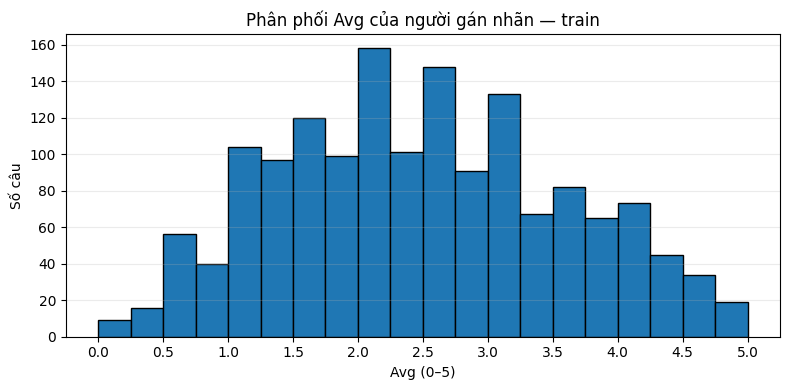

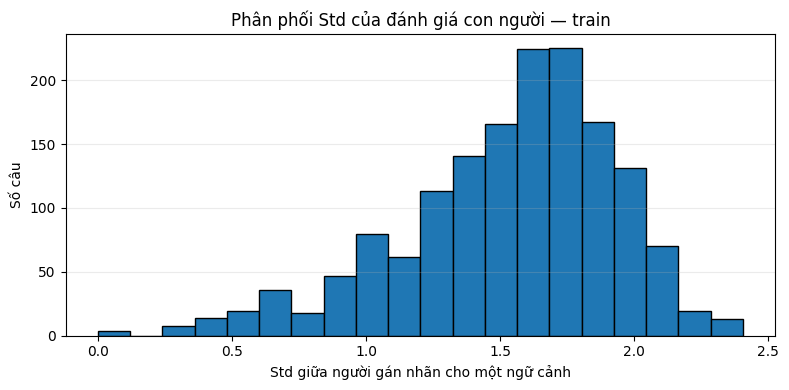

In [5]:
labeled_splits = {name: df for name, df in DATASETS.items() if "Avg" in df.columns}

for split_name, df in labeled_splits.items():
    print(f"\nĐiểm số — {split_name}")
    print(df[[c for c in ["Avg", "Std"] if c in df.columns]].describe().T)

    if df["Avg"].notna().any():
        plt.figure(figsize=(8, 4))
        plt.hist(df["Avg"].dropna(), bins=np.linspace(0, 5, 21), edgecolor="black")
        plt.title(f"Phân phối Avg của người gán nhãn — {split_name}")
        plt.xlabel("Avg (0–5)")
        plt.ylabel("Số câu")
        plt.xticks(np.arange(0, 5.1, 0.5))
        plt.grid(axis="y", alpha=0.25)
        plt.tight_layout()
        plt.show()

    if "Std" in df.columns and df["Std"].notna().any():
        plt.figure(figsize=(8, 4))
        plt.hist(df["Std"].dropna(), bins=20, edgecolor="black")
        plt.title(f"Phân phối Std của đánh giá con người — {split_name}")
        plt.xlabel("Std giữa người gán nhãn cho một ngữ cảnh")
        plt.ylabel("Số câu")
        plt.grid(axis="y", alpha=0.25)
        plt.tight_layout()
        plt.show()

## 6. Mỗi particle verb có bao nhiêu ngữ cảnh?

Phần này phân tích số câu trên mỗi target. Các giá trị này giúp nhóm hiểu độ phủ của dữ liệu và phát hiện target có quá ít ví dụ.


Số câu trên mỗi target — train


,count,mean,std,min,25%,50%,75%,max
n_contexts,158.0,9.85443,0.712276,5.0,10.0,10.0,10.0,10.0


Các target có nhiều ngữ cảnh nhất:


,ParticleVerb,n_contexts,mean_Avg,std_Avg_across_contexts,mean_annotator_Std,Base,Particle
0,add up,10,2.680202,0.916388,1.606381,add,up
1,back down,10,1.552223,0.610180,1.567686,back,down
2,back off,10,2.292222,0.789125,1.613740,back,off
4,be out,10,2.110000,1.009345,1.563762,be,out
5,blow off,10,2.140000,1.157776,1.480890,blow,off
6,blow up,10,2.259091,1.007030,1.620802,blow,up
7,boil down,10,1.790000,0.871079,1.473027,boil,down
8,bounce off,10,3.050000,0.870823,1.608074,bounce,off
9,break down,10,2.442222,1.145167,1.426816,break,down
10,break off,10,2.306667,1.236961,1.561841,break,off


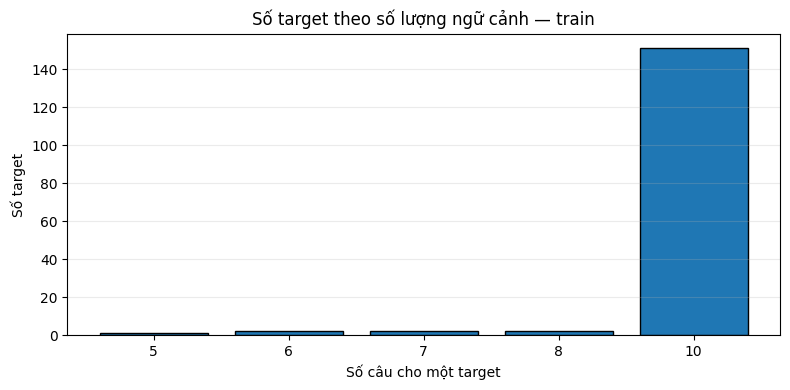

In [6]:
def summarize_targets(df: pd.DataFrame) -> pd.DataFrame:
    """Tóm tắt theo biểu thức ParticleVerb; các cột nhãn chỉ được tính khi có trong split."""
    if "ParticleVerb" not in df.columns:
        raise KeyError("Không có cột ParticleVerb trong dataframe.")
    agg = {
        "n_contexts": ("ContextID", "size") if "ContextID" in df.columns else ("ParticleVerb", "size"),
    }
    for col, new_name in [("Avg", "mean_Avg"), ("Avg", "std_Avg_across_contexts"), ("Std", "mean_annotator_Std")]:
        if col in df.columns:
            if new_name == "mean_Avg":
                agg[new_name] = (col, "mean")
            elif new_name == "std_Avg_across_contexts":
                agg[new_name] = (col, "std")
            else:
                agg[new_name] = (col, "mean")
    for col in ["Base", "Particle"]:
        if col in df.columns:
            agg[col] = (col, "first")
    out = df.groupby("ParticleVerb", dropna=False).agg(**agg).reset_index()
    return out.sort_values(["n_contexts", "ParticleVerb"], ascending=[False, True])

TARGET_SUMMARIES = {}
for split_name, df in DATASETS.items():
    if "ParticleVerb" not in df.columns:
        continue
    summary = summarize_targets(df)
    TARGET_SUMMARIES[split_name] = summary
    print(f"\nSố câu trên mỗi target — {split_name}")
    display(summary["n_contexts"].describe().to_frame().T)
    print("Các target có nhiều ngữ cảnh nhất:")
    display(summary.head(10))

    plt.figure(figsize=(8, 4))
    counts = summary["n_contexts"].value_counts().sort_index()
    plt.bar(counts.index.astype(str), counts.values, edgecolor="black")
    plt.title(f"Số target theo số lượng ngữ cảnh — {split_name}")
    plt.xlabel("Số câu cho một target")
    plt.ylabel("Số target")
    plt.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()

## 7. Phân tích variation theo ngữ cảnh

Đối với mục tiêu nghiên cứu này, một target có nhiều câu khác nhau và điểm `Avg` có thể thay đổi theo câu. `std_Avg_across_contexts` đo độ lệch chuẩn của điểm trung bình người gán nhãn **giữa các ngữ cảnh của cùng target**. Đây là đại lượng khác với cột `Std`, vốn đo độ bất đồng giữa người gán nhãn trong một ngữ cảnh.


Variation giữa các ngữ cảnh — train


,count,mean,std,min,25%,50%,75%,max
std_Avg_across_contexts,158.0,0.749935,0.266344,0.233095,0.534243,0.73045,0.90635,1.637206


Targets có điểm Avg biến thiên lớn nhất giữa các ngữ cảnh:


,ParticleVerb,n_contexts,mean_Avg,std_Avg_across_contexts,mean_annotator_Std,Base,Particle
93,pull off,10,3.040000,1.637206,1.504880,pull,off
95,pull up,10,3.585556,1.401450,1.353484,pull,up
42,fall off,10,3.192222,1.367746,1.506820,fall,off
99,rip off,10,2.335556,1.342212,1.481536,rip,off
32,cut off,10,2.481111,1.334578,1.584767,cut,off
31,cut down,10,2.631111,1.252178,1.652289,cut,down
10,break off,10,2.306667,1.236961,1.561841,break,off
23,come down,10,2.910000,1.228775,1.452927,come,down
19,catch up,10,1.516666,1.222158,1.337477,catch,up
43,fall out,10,2.451111,1.212059,1.774252,fall,out


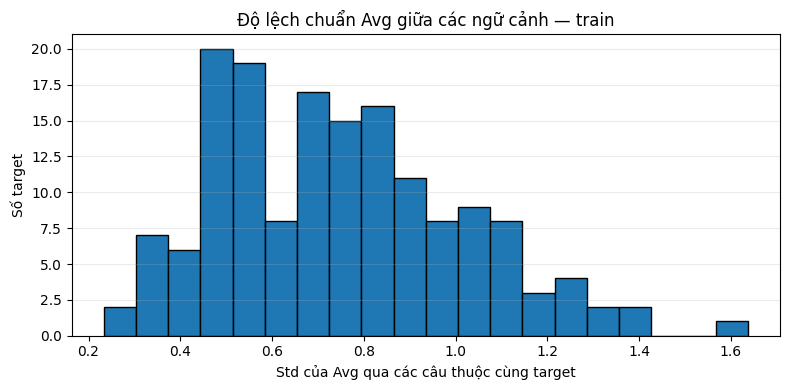

In [7]:
for split_name, summary in TARGET_SUMMARIES.items():
    if "std_Avg_across_contexts" not in summary.columns:
        print(f"Bỏ qua {split_name}: không có cột Avg để phân tích variation.")
        continue

    available = summary.dropna(subset=["std_Avg_across_contexts"])
    print(f"\nVariation giữa các ngữ cảnh — {split_name}")
    display(available["std_Avg_across_contexts"].describe().to_frame().T)

    print("Targets có điểm Avg biến thiên lớn nhất giữa các ngữ cảnh:")
    display(available.sort_values("std_Avg_across_contexts", ascending=False).head(15))

    plt.figure(figsize=(8, 4))
    plt.hist(available["std_Avg_across_contexts"].dropna(), bins=20, edgecolor="black")
    plt.title(f"Độ lệch chuẩn Avg giữa các ngữ cảnh — {split_name}")
    plt.xlabel("Std của Avg qua các câu thuộc cùng target")
    plt.ylabel("Số target")
    plt.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()

## 8. Những particle verbs và particles thường gặp

Đây là thống kê mô tả tần suất trong tập dữ liệu, không phải kết luận rằng các target phổ biến hơn sẽ dễ dự đoán hơn.

In [8]:
for split_name, df in DATASETS.items():
    print(f"\n===== {split_name} =====")
    if "ParticleVerb" in df.columns:
        print("ParticleVerb xuất hiện nhiều dòng nhất:")
        display(df["ParticleVerb"].value_counts(dropna=False).head(15).rename_axis("ParticleVerb").reset_index(name="n_contexts"))
    if "Particle" in df.columns:
        print("Phân phối cột Particle:")
        display(df["Particle"].value_counts(dropna=False).head(20).rename_axis("Particle").reset_index(name="n_rows"))
    if "Base" in df.columns:
        print("Phân phối cột Base:")
        display(df["Base"].value_counts(dropna=False).head(20).rename_axis("Base").reset_index(name="n_rows"))


===== train =====
ParticleVerb xuất hiện nhiều dòng nhất:


,ParticleVerb,n_contexts
0,boil down,10
1,strike down,10
2,take down,10
3,tear down,10
4,back down,10
5,come down,10
6,cut down,10
7,put down,10
8,break down,10
9,let down,10


Phân phối cột Particle:


,Particle,n_rows
0,up,427
1,down,406
2,out,388
3,off,336


Phân phối cột Base:


,Base,n_rows
0,come,40
1,break,40
2,pull,40
3,set,40
4,walk,40
5,take,30
6,cut,30
7,run,30
8,shut,30
9,throw,30


## 9. Độ dài câu và ví dụ cho từng target

Độ dài câu chỉ là đặc trưng mô tả ban đầu. Không nên tự động kết luận câu dài thì mô hình sẽ kém hơn; điều đó cần được kiểm tra thực nghiệm.


Độ dài câu theo số token cách nhau bởi khoảng trắng — train


,count,mean,std,min,25%,50%,75%,max
n_whitespace_tokens,1557.0,24.382787,9.350428,8.0,17.0,24.0,31.0,46.0


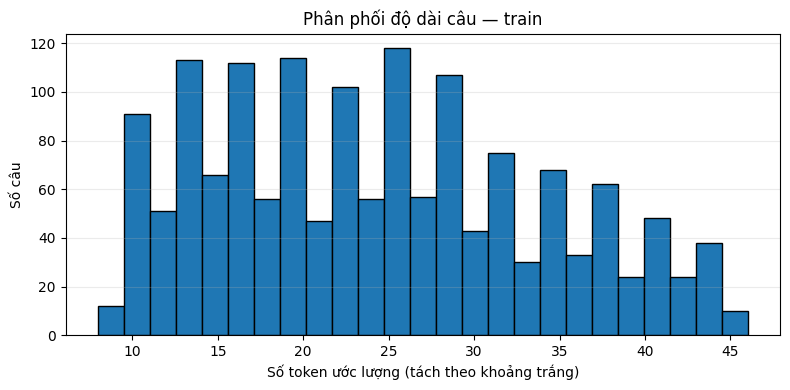

Ví dụ gọi hàm: show_target_examples('take off', split='train')


In [9]:
for split_name, df in DATASETS.items():
    if "Context" not in df.columns:
        continue
    temp = df["Context"].astype("string")
    context_lengths = temp.str.split().str.len()
    print(f"\nĐộ dài câu theo số token cách nhau bởi khoảng trắng — {split_name}")
    display(context_lengths.describe().to_frame("n_whitespace_tokens").T)

    plt.figure(figsize=(8, 4))
    plt.hist(context_lengths.dropna(), bins=25, edgecolor="black")
    plt.title(f"Phân phối độ dài câu — {split_name}")
    plt.xlabel("Số token ước lượng (tách theo khoảng trắng)")
    plt.ylabel("Số câu")
    plt.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()


def show_target_examples(target: str, split: str = "train", max_rows: int = 20):
    """Hiển thị ngữ cảnh và nhãn của một target; split phải trùng tên tệp đã nạp."""
    if split not in DATASETS:
        raise KeyError(f"Không có split {split!r}. Các lựa chọn: {list(DATASETS)}")
    df = DATASETS[split]
    if "ParticleVerb" not in df.columns:
        raise KeyError("Split này không có cột ParticleVerb.")
    subset = df.loc[df["ParticleVerb"].astype("string").str.casefold() == str(target).casefold()]
    cols = [c for c in ["ContextID", "ParticleVerb", "Base", "Particle", "Avg", "Std", "Context"] if c in subset.columns]
    if subset.empty:
        print(f"Không tìm thấy target {target!r} trong split {split!r}.")
    else:
        display(subset[cols].head(max_rows))

print("Ví dụ gọi hàm: show_target_examples('take off', split='train')")

In [11]:
show_target_examples('boil down', split='train')

,ContextID,ParticleVerb,Base,Particle,Avg,Std,Context
1,30002,boil down,boil,down,0.3,0.483046,His philosophy of life may be boiled down into a single sentence: Carry on and you will be happy.
6,30007,boil down,boil,down,0.7,1.059350,"The Rehabilitation of Offenders Act has been around since 1975, yet when it boils down to it, it is little better than useless with no real teeth."
45,30046,boil down,boil,down,1.5,1.080120,"This is, of course all boiling down to NIMBYism - because something does n't directly affect someone, therefore they do n't understand the limitations."
49,30050,boil down,boil,down,1.5,1.649920,It is the essence of ALLEN 'S Voluminous speech es boiled down to the smallest possible dimensions.
50,30051,boil down,boil,down,1.5,1.715940,"What this all boils down to is that "" The Cruel Sea "" is a surprisingly good movie and stands out as something a bit special when it comes to the war movies which focus on Worl..."
64,30065,boil down,boil,down,1.7,1.766980,""" Which boiled down to a philosopher able to confound the average hard core Christian of her time; like an intelligent man overturning the base hatred of a Nazi of the 30 s."
161,30162,boil down,boil,down,2.6,1.646550,"The key product of the whale was its blubber which could be boiled down to produce an oil used for lighting street lamps, to lubricate machinery and in soap."
164,30165,boil down,boil,down,2.6,1.776390,"It is evident, however, that they soon gave up this delusion, and that for want of the genuine...... cuit, or cooked wine, which had at all times been cleverly prepared by boil..."
184,30185,boil down,boil,down,2.7,2.002780,"To-day, after the heat had cooked it and boiled it down, the swing into the Hoosier circle by Mr. Hill seemed a good dual smaller than it was last night."
188,30189,boil down,boil,down,2.8,1.549190,"-- The drug known as catechu is principally prepared from this tree, the wood of which is boiled down, and the decoction subsequently evaporated so as to form an extract much ..."


## 10. Kiểm tra chồng lấn target giữa các split

Trong bộ dữ liệu chính thức, việc chia dữ liệu được thực hiện ở cấp target. Do đó train và test/evaluation chính thức không nên có target trùng nhau. Nếu notebook phát hiện chồng lấn, hãy kiểm tra xem có đang trộn trial data với main data hoặc đọc nhầm tệp hay không.

In [12]:
train_name = next((name for name in DATASETS if name.lower() == "train"), None)
if train_name is None:
    print("Không nhận diện được split 'train' theo tên tệp; bỏ qua kiểm tra train–test.")
else:
    train_targets = set(DATASETS[train_name]["ParticleVerb"].dropna().astype(str).str.casefold())
    other_splits = [name for name in DATASETS if name != train_name]
    for split_name in other_splits:
        other_targets = set(DATASETS[split_name]["ParticleVerb"].dropna().astype(str).str.casefold())
        overlap = sorted(train_targets & other_targets)
        print(f"Train vs {split_name}: {len(overlap)} target trùng")
        if overlap:
            print("Một vài target trùng:", overlap[:20])
        else:
            print("Không phát hiện target trùng.")

## 11. Chuẩn bị validation nội bộ theo target (không bắt buộc)

Khi nhóm bắt đầu huấn luyện mô hình, nên tạo validation từ tập train bằng cách giữ toàn bộ câu của một `ParticleVerb` ở cùng một split. Cell dưới đây tạo một phép chia 80/20 có seed cố định ở **cấp target** để phục vụ thử nghiệm ban đầu. Nó không thay đổi các tệp TSV gốc.

In [13]:
if train_name is None:
    print("Cần có tệp en-pv-train.tsv để tạo validation nội bộ.")
else:
    train_df = DATASETS[train_name].copy()
    targets = train_df["ParticleVerb"].dropna().astype(str).unique().tolist()
    rng = np.random.default_rng(RANDOM_SEED)
    rng.shuffle(targets)
    n_val = max(1, int(round(0.20 * len(targets)))) if len(targets) > 1 else 0
    val_targets = set(targets[:n_val])

    internal_train = train_df.loc[~train_df["ParticleVerb"].astype(str).isin(val_targets)].copy()
    internal_val = train_df.loc[train_df["ParticleVerb"].astype(str).isin(val_targets)].copy()

    print(f"Train gốc: {len(train_df)} câu, {train_df['ParticleVerb'].nunique()} targets")
    print(f"Internal train: {len(internal_train)} câu, {internal_train['ParticleVerb'].nunique()} targets")
    print(f"Internal val: {len(internal_val)} câu, {internal_val['ParticleVerb'].nunique()} targets")
    print("Target overlap:", len(set(internal_train["ParticleVerb"]) & set(internal_val["ParticleVerb"])))
    print("\nGhi chú: đây là một phép chia ngẫu nhiên đơn giản theo target; với số target ít, các kết quả có thể dao động đáng kể. Nên thử nhiều seed hoặc cross-validation theo nhóm nếu phù hợp.")

Train gốc: 1557 câu, 158 targets
Internal train: 1243 câu, 126 targets
Internal val: 314 câu, 32 targets
Target overlap: 0

Ghi chú: đây là một phép chia ngẫu nhiên đơn giản theo target; với số target ít, các kết quả có thể dao động đáng kể. Nên thử nhiều seed hoặc cross-validation theo nhóm nếu phù hợp.


## 12. Tạo bảng tổng hợp và lưu kết quả EDA (tùy chọn)

Bật `SAVE_OUTPUTS = True` nếu muốn lưu bảng thống kê theo target thành CSV để đưa vào báo cáo. Mặc định tắt để notebook không tự ghi tệp.

In [16]:
SAVE_OUTPUTS = True
OUTPUT_DIR = Path("eda_outputs")

if SAVE_OUTPUTS:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    split_summary.to_csv(OUTPUT_DIR / "split_summary.csv", index=False)
    quality_summary.to_csv(OUTPUT_DIR / "quality_summary.csv", index=False)
    for split_name, summary in TARGET_SUMMARIES.items():
        safe_name = re.sub(r"[^A-Za-z0-9_-]+", "_", split_name)
        summary.to_csv(OUTPUT_DIR / f"target_summary_{safe_name}.csv", index=False)
    print(f"Đã lưu kết quả vào: {OUTPUT_DIR.resolve()}")
else:
    print("SAVE_OUTPUTS=False nên chưa lưu tệp nào.")

Đã lưu kết quả vào: C:\Users\MrBeast\Desktop\CS529\notebooks\eda_outputs


## 13. Checklist sau khi chạy notebook

Sau khi chạy các cell từ trên xuống, nhóm nên ghi lại:

- [ ] Số câu và số target thực tế trong `en-pv-train.tsv`.
- [ ] Số target/câu trong từng split; có những tệp nào và chúng có nhãn `Avg`/`Std` không?
- [ ] Phân phối `Avg`: lệch về điểm thấp, điểm cao hay tương đối đều? Có điểm nằm ngoài 0–5 không?
- [ ] Trung bình số ngữ cảnh trên mỗi target và các target có số câu ít nhất.
- [ ] `Std` của người gán nhãn (mức bất đồng trong một câu) và độ lệch chuẩn `Avg` qua ngữ cảnh của cùng target khác nhau thế nào?
- [ ] Có target bị trùng giữa train và evaluation/test không?
- [ ] Có cần xử lý dữ liệu thiếu hoặc bất thường không? Ghi rõ lý do, đừng âm thầm xóa.

### Ghi nhớ cho nghiên cứu
Notebook EDA không tự quyết định phương pháp mô hình. Nó giúp nhóm hiểu dữ liệu trước khi đọc survey và chọn phương pháp. Khi chuyển sang mô hình hóa, hãy so sánh baseline phù hợp, giữ việc chia dữ liệu ở cấp target, và báo cáo riêng Spearman, RMSE cùng context-variance correlation theo định nghĩa chính thức của ban tổ chức.